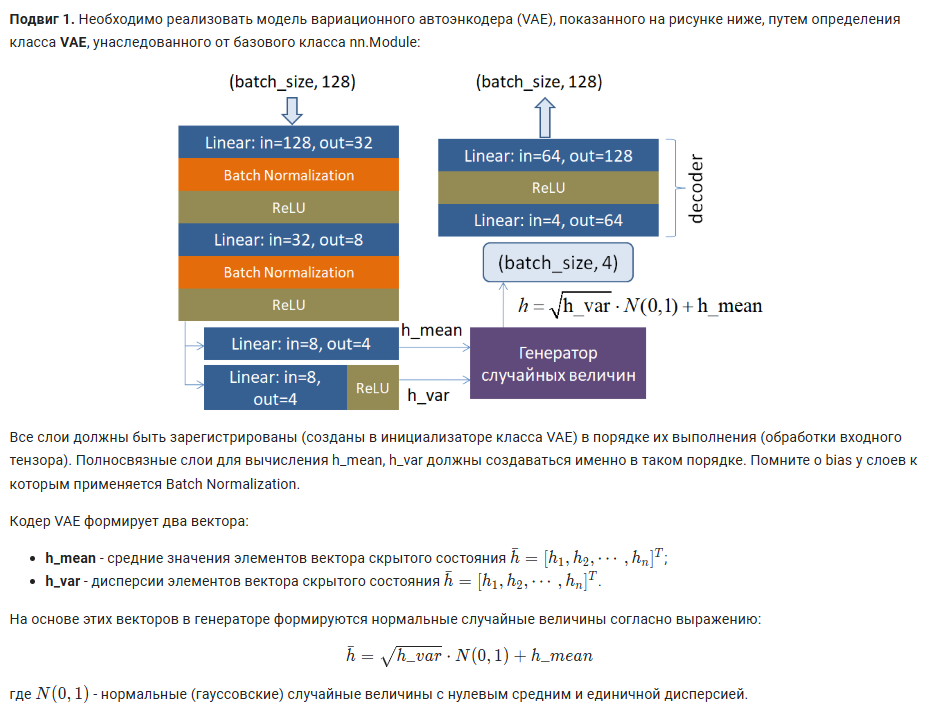

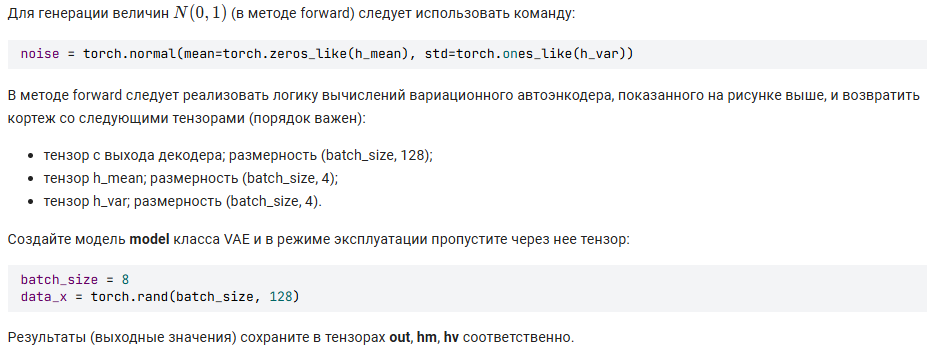

In [7]:
import torch
import torch.nn as nn

# здесь объявляйте класс VAE
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(128, 32, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 8, bias=False),
            nn.BatchNorm1d(8),
            nn.ReLU()
        )
        
        self.means = nn.Linear(8, 4)
        self.vars = nn.Sequential(nn.Linear(8, 4), nn.ReLU())
        
        self.decoder = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Linear(64, 128)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        
        h_mean = self.means(encoded) 
        h_var = self.vars(encoded) 

        noise = torch.normal(mean=torch.zeros_like(h_mean), std=torch.ones_like(h_var))
        h = noise*h_var**0.5 + h_mean
        x = self.decoder(h)

        return x, h_mean, h_var


# тензор data_x в программе не менять
batch_size = 8
data_x = torch.rand(batch_size, 128)

# здесь создавайте модель и продолжайте программу
model = VAE()
model.eval()
out, hm, hv = model(data_x)
out

tensor([[ 6.7535e-02, -9.1872e-02,  7.7757e-02,  ..., -1.6708e-01,
         -2.4229e-02,  6.6559e-02],
        [ 6.6704e-02, -1.4988e-02,  1.0100e-01,  ..., -1.0462e-01,
         -5.9451e-03,  4.6323e-02],
        [ 1.1355e-01, -3.7468e-02,  1.0249e-01,  ..., -1.1607e-01,
         -1.2271e-03,  4.5363e-02],
        ...,
        [ 1.3706e-01, -6.4151e-02,  1.6969e-01,  ..., -2.0052e-01,
          5.9325e-02,  1.1751e-01],
        [ 1.5481e-01,  4.8144e-03,  1.2272e-01,  ..., -5.9379e-02,
          1.5384e-02,  1.1731e-02],
        [ 8.2280e-02,  9.6375e-02,  9.8480e-02,  ...,  7.0222e-06,
          7.5341e-03, -1.5689e-02]], grad_fn=<AddmmBackward0>)

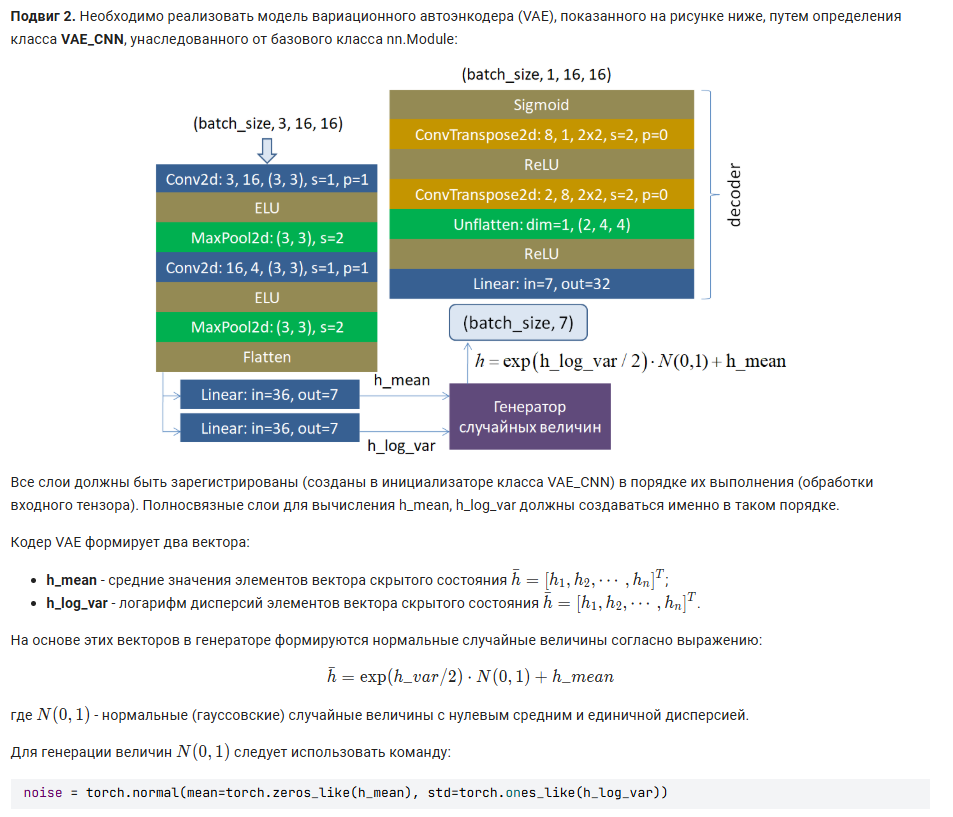

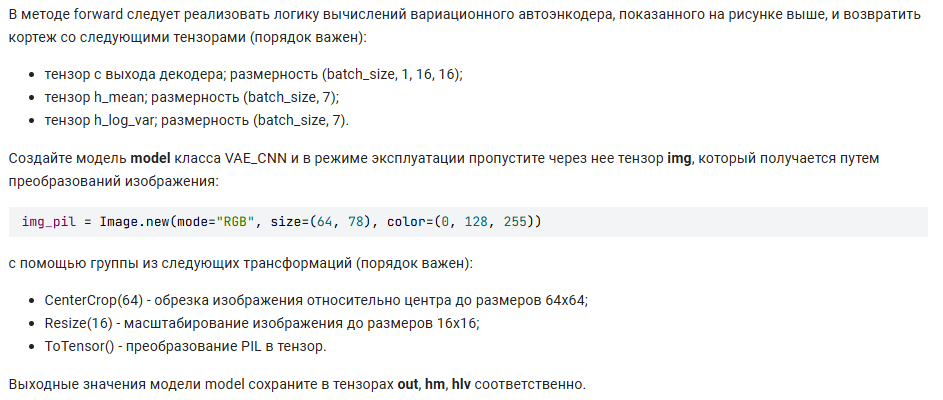

In [40]:
from PIL import Image
import torch
import torch.nn as nn
import torchvision.transforms as tfs
# import torchvision.transforms.v2 as tfs_v2 - недоступен на Stepik

# здесь объявляйте класс VAE
class VAE_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.ELU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(in_channels=16, out_channels=4, kernel_size=3, stride=1, padding=1),
            nn.ELU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Flatten()
        )
        
        self.means = nn.Linear(36, 7)
        self.vars = nn.Linear(36, 7)
        
        self.decoder = nn.Sequential(
            nn.Linear(7, 32),
            nn.ReLU(),
            nn.Unflatten(dim=1, unflattened_size=(2, 4, 4)),
            nn.ConvTranspose2d(in_channels=2, out_channels=8, kernel_size=2, stride=2, padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=8, out_channels=1, kernel_size=2, stride=2, padding=0),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        
        h_mean = self.means(encoded)
        h_log_var = self.vars(encoded)

        noise = torch.normal(mean=torch.zeros_like(h_mean), std=torch.ones_like(h_log_var))
        h  = noise*torch.exp(h_log_var /2) + h_mean
        x = self.decoder(h)

        return x, h_mean, h_log_var 


# здесь создавайте модель и продолжайте программу
model = VAE_CNN()

img_pil = Image.new(mode="RGB", size=(64, 78), color=(0, 128, 255))

# img_pil = tfs.CenterCrop(64)(img_pil)
# img_pil = tfs.Resize(16)(img_pil)
# img_pil = tfs.ToTensor()(img_pil)

tr = tfs.Compose([tfs.CenterCrop(64), tfs.Resize(16), tfs.ToTensor()])
img = tr(img_pil)

model.eval()
out, hm, hlv = model(img.unsqueeze(0))
out

tensor([[[[0.4921, 0.4910, 0.4850, 0.4737, 0.4917, 0.4882, 0.4806, 0.4698,
           0.4804, 0.4687, 0.4755, 0.4636, 0.4675, 0.4656, 0.4824, 0.4709],
          [0.4687, 0.4449, 0.4140, 0.4571, 0.4654, 0.4477, 0.4169, 0.4541,
           0.4559, 0.4509, 0.4447, 0.4509, 0.4554, 0.4369, 0.4434, 0.4451],
          [0.5080, 0.5616, 0.4633, 0.4703, 0.4983, 0.5341, 0.4603, 0.4614,
           0.4760, 0.4647, 0.4709, 0.4598, 0.4874, 0.5026, 0.4841, 0.4766],
          [0.4297, 0.5154, 0.4674, 0.4537, 0.4340, 0.4939, 0.4634, 0.4470,
           0.4483, 0.4489, 0.4546, 0.4473, 0.4325, 0.4810, 0.4611, 0.4620],
          [0.4761, 0.4625, 0.4761, 0.4625, 0.4846, 0.4753, 0.4750, 0.4645,
           0.4791, 0.4667, 0.4757, 0.4633, 0.4656, 0.4612, 0.4804, 0.4677],
          [0.4543, 0.4509, 0.4543, 0.4509, 0.4577, 0.4525, 0.4364, 0.4509,
           0.4554, 0.4504, 0.4473, 0.4509, 0.4538, 0.4443, 0.4560, 0.4451],
          [0.4761, 0.4625, 0.4761, 0.4625, 0.4766, 0.4689, 0.4663, 0.4574,
           0.4759, 

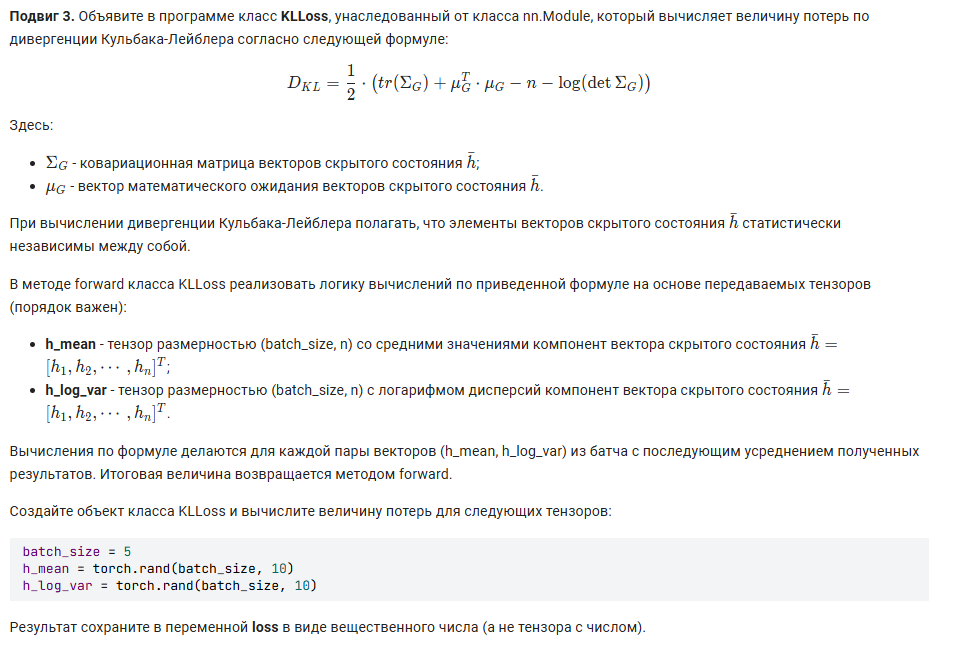

In [41]:
import torch
import torch.nn as nn

# здесь объявляйте класс KLLoss
class KLLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, h_mean, h_log_var):
        kl_loss = -0.5 * torch.sum(1 + h_log_var - h_mean ** 2 - torch.exp(h_log_var), dim=-1)
        return torch.mean(kl_loss)
        
        

batch_size = 5
h_mean = torch.rand(batch_size, 10)
h_log_var = torch.rand(batch_size, 10)

# здесь продолжайте программу
loss_func = KLLoss()
loss = loss_func(h_mean, h_log_var).item()
loss

2.8623764514923096

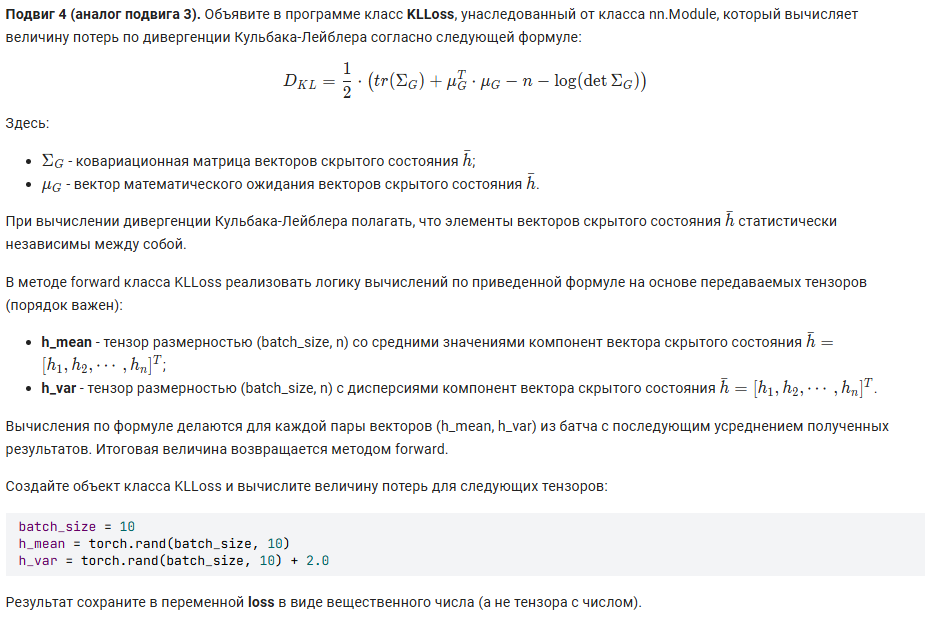

In [ ]:
import torch
import torch.nn as nn

# здесь объявляйте класс KLLoss
class KLLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, h_mean, h_var):
        kl_loss = 0.5 * torch.sum(h_var + h_mean ** 2 - 1 - torch.log(h_var), dim=-1)
        return torch.mean(kl_loss)

batch_size = 10
h_mean = torch.rand(batch_size, 10)
h_var = torch.rand(batch_size, 10) + 2.0

# здесь продолжайте программу
loss_func = KLLoss()
loss = loss_func(h_mean, h_var).item()
loss

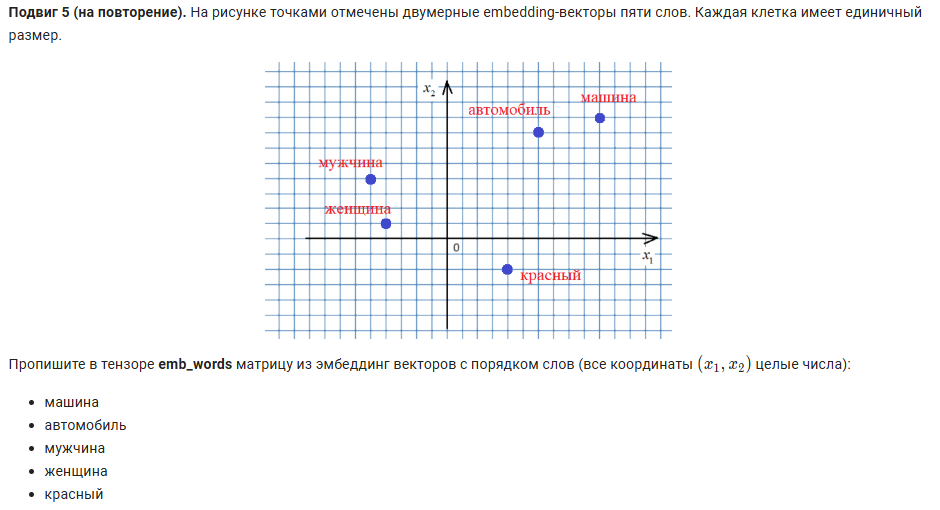

In [43]:
import torch

emb_words = torch.tensor([[10, 8], [6, 7], [-5, 4], [-4, 1], [4, -2]], dtype=torch.int)



In [52]:
import torch
import torch.nn as nn

emb_layer = nn.Embedding(20, 8)
num_word = torch.LongTensor([11])
# batch_words = torch.LongTensor([1, 2, 10, 5])
# word_emb = emb_layer(num_word)
# word_emb_batch = emb_layer(batch_words)

In [53]:
emb_layer(num_word)

tensor([[ 0.1822,  0.0149, -1.1746,  0.3399,  0.3743, -0.9449, -0.3300, -0.2640]],
       grad_fn=<EmbeddingBackward0>)